<a href="https://colab.research.google.com/github/miguelcuero-ai/Fisica-computacional-2026-2/blob/main/Taller%203/Taller_3_FC_Minimos_Cuadrados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!apt-get -qq install gfortran

In [ ]:
!gfortran --version

GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
Copyright (C) 2023 Free Software Foundation, Inc.
This is free software; see the source for copying conditions.  There is NO
warranty; not even for MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.



##PUNTO A: Limpieza de datos

1. Abra `100_mediciones_pendulo_minimos_cuadrados.xlsx` y revise la hoja `Datos_estudiantes`.
2. Ejecute el script de limpieza suministrado por el profesor.
3. Complete sus tres tareas: correcciones justificadas, elección del ángulo máximo y exclusiones manuales.
4. No excluya un dato únicamente porque se aleja de la tendencia. Toda corrección o exclusión debe apoyarse en la información experimental.
5. El script debe generar `pendulo_limpio.dat` e `informe_limpieza.xlsx`.

In [ ]:
"""Limpieza de mediciones de un péndulo y exportación para Fortran."""

from pathlib import Path
import pandas as pd

ARCHIVO_ENTRADA = Path("100_mediciones_pendulo_minimos_cuadrados.xlsx")
HOJA = "Datos_estudiantes"

if not ARCHIVO_ENTRADA.exists():
    raise FileNotFoundError(f"No se encontró {ARCHIVO_ENTRADA}.")

datos = pd.read_excel(ARCHIVO_ENTRADA, sheet_name=HOJA)

columnas_requeridas = [
    "medicion_id",
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
    "observador",
    "observacion_campo",
    "calidad_video",
]

columnas_ausentes = [col for col in columnas_requeridas if col not in datos.columns]
if columnas_ausentes:
    raise ValueError("Faltan columnas obligatorias: " + ", ".join(columnas_ausentes))

datos_originales = datos.copy(deep=True)

# 2. COLUMNAS PARA DOCUMENTAR LA LIMPIEZA
datos["incluir"] = True
datos["accion_limpieza"] = "Conservar"
datos["justificacion"] = "Medición aceptada"

def excluir_registros(condicion, justificacion):
    nuevos = condicion.fillna(False) & datos["incluir"]
    datos.loc[nuevos, "incluir"] = False
    datos.loc[nuevos, "accion_limpieza"] = "Excluir"
    datos.loc[nuevos, "justificacion"] = justificacion

# ============================================================
# 3. CORRECCIONES JUSTIFICADAS (TODO 1)
# ============================================================
correcciones_longitud = {
    52: 70  # Se corrigió el cero adicional (700 -> 70 cm)
}

correcciones_tiempo = {
    23: 19.06,  # Se registró el período en lugar del tiempo total (1.906 * 10)
    81: 18.53   # Se registró el período en lugar del tiempo total (1.853 * 10)
}

for medicion_id, valor in correcciones_longitud.items():
    condicion = datos["medicion_id"] == medicion_id
    if condicion.any():
        datos.loc[condicion, "longitud_cm"] = valor
        datos.loc[condicion, "accion_limpieza"] = "Corregir longitud"
        datos.loc[condicion, "justificacion"] = "Error de registro identificado y corregido"

for medicion_id, valor in correcciones_tiempo.items():
    condicion = datos["medicion_id"] == medicion_id
    if condicion.any():
        datos.loc[condicion, "tiempo_medido_s"] = valor
        datos.loc[condicion, "accion_limpieza"] = "Corregir tiempo"
        datos.loc[condicion, "justificacion"] = "El valor registrado no correspondía al tiempo total"

# 4. EXCLUSIONES AUTOMÁTICAS
excluir_registros(datos["tiempo_medido_s"].isna(), "No existe un tiempo medido")
excluir_registros(
    datos["numero_oscilaciones"].isna() | (datos["numero_oscilaciones"] <= 0),
    "Número de oscilaciones ausente o no positivo",
)

# ============================================================
# 5. DOMINIO DE VALIDEZ DEL MODELO (TODO 2)
# ============================================================
ANGULO_MAXIMO = 15.0

excluir_registros(
    datos["angulo_inicial_deg"].isna() | (datos["angulo_inicial_deg"].abs() > ANGULO_MAXIMO),
    "Fuera de la aproximación de ángulo pequeño",
)

# 6. BÚSQUEDA DE REGISTROS DUPLICADOS
variables_experimentales = [
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
    "observador",
]

duplicados = pd.Series(False, index=datos.index)
indices_aceptados = datos.index[datos["incluir"]]
duplicados.loc[indices_aceptados] = datos.loc[indices_aceptados].duplicated(
    subset=variables_experimentales, keep="first"
)
excluir_registros(duplicados, "Registro experimental duplicado")

# ============================================================
# 8. EXCLUSIONES MANUALES (TODO 3)
# ============================================================
exclusiones_manuales = {
    36: "Pérdida temporal del marcador en el video / Calidad baja",
    45: "El cronómetro inició tarde según observación de campo",
    77: "Pérdida temporal del marcador en el video / Calidad baja",
    88: "Número de oscilaciones ambiguo registrado en campo"
}

for medicion_id, razon in exclusiones_manuales.items():
    condicion = datos["medicion_id"] == medicion_id
    if condicion.any():
        datos.loc[condicion, "incluir"] = False
        datos.loc[condicion, "accion_limpieza"] = "Excluir"
        datos.loc[condicion, "justificacion"] = razon

# 9. CONSTRUCCIÓN DEL CONJUNTO LIMPIO
datos_limpios = datos.loc[datos["incluir"]].copy()

# 10. EXPORTACIÓN PARA FORTRAN
columnas_fortran = [
    "medicion_id",
    "longitud_cm",
    "angulo_inicial_deg",
    "numero_oscilaciones",
    "tiempo_medido_s",
]

datos_limpios[columnas_fortran].to_csv(
    "pendulo_limpio.dat",
    sep=" ",
    index=False,
    header=False,
    float_format="%.6f",
)

# 11. INFORME DE LIMPIEZA
columnas_informe = ["medicion_id", "incluir", "accion_limpieza", "justificacion"]
datos[columnas_informe].to_excel("informe_limpieza.xlsx", index=False)

print(f"Registros originales: {len(datos_originales)}")
print(f"Registros aceptados: {len(datos_limpios)}")  # Produce exactamente 89
print(f"Registros excluidos: {len(datos) - len(datos_limpios)}")

Registros originales: 100
Registros aceptados: 89
Registros excluidos: 11


## Parte B. Programa en Fortran 2008

Realice el diagrama de flujo respectivo y escriba el programa `ajuste_pendulo.f90`. El programa debe:

1. Abrir `pendulo_limpio.dat` y comprobar que el archivo se abrió correctamente.
2. Leer un número desconocido de filas mediante un ciclo y `iostat`.
3. Convertir cada longitud de centímetros a metros.
4. Calcular $T$ y construir $x=L$ y $y=T^2$.
5. Acumular $N$, $s_x$, $s_y$, $s_{xx}$ y $s_{xy}$.
6. Calcular la pendiente $a$ y el intercepto $b$.
7. Estimar $g=4\pi^2/a$.
8. Realizar una segunda lectura del archivo para calcular $R^2$.
9. Mostrar claramente $N$, $a$, $b$, $R^2$ y $g$, incluyendo unidades.
10. Escribir esos cinco valores, en ese orden y sin encabezado, en `resultados_ajuste.dat`.
11. Detectar al menos estos errores: archivo inexistente, menos de dos datos y denominador nulo.

Para estandarizar el archivo que revisará la celda PASS/FAIL, declare una unidad de salida entera y use al final del programa:

```fortran
open(newunit=unidad_salida, file='resultados_ajuste.dat', &
     status='replace', action='write')
write(unidad_salida, *) n, a, b, r2, g
close(unidad_salida)
```

Compile con advertencias y comprobaciones activadas:

```bash
gfortran -std=f2008 -Wall -Wextra -fcheck=all -o ajuste_pendulo ajuste_pendulo.f90
./ajuste_pendulo
```

In [ ]:
%%writefile ajuste_pendulo.f90
program ajuste_pendulo
  use iso_fortran_env, only: real64
  implicit none

  ! Declaración de variables básicas
  integer :: unidad_in, unidad_salida, estado
  integer :: id, n_osc, n

  real(real64) :: longitud_cm, angulo_deg, tiempo_s
  real(real64) :: x, y, periodo_s, y_pred, y_media
  real(real64) :: sx, sy, sxx, sxy, den
  real(real64) :: a, b, r2, g
  real(real64) :: sse, sst

  real(real64), parameter :: pi = 3.14159265358979323846_real64

  ! ===================================================================
  ! PUNTO 1: Abrir pendulo_limpio.dat y comprobar lectura inicial
  ! ===================================================================
  open(newunit=unidad_in, file='pendulo_limpio.dat', status='old', &
       action='read', iostat=estado)

  if (estado /= 0) then
     print *, 'Error al intentar abrir el archivo pendulo_limpio.dat'
     stop
  end if

  ! ===================================================================
  ! PUNTO 2-5: Lectura, conversiones y acumuladores
  ! ===================================================================
  n   = 0
  sx  = 0.0_real64
  sy  = 0.0_real64
  sxx = 0.0_real64
  sxy = 0.0_real64

  do
     read(unidad_in, *, iostat=estado) id, longitud_cm, angulo_deg, n_osc, tiempo_s
     if (estado /= 0) exit

     x = longitud_cm / 100.0_real64
     periodo_s = tiempo_s / real(n_osc, real64)
     y = periodo_s**2

     n   = n + 1
     sx  = sx + x
     sy  = sy + y
     sxx = sxx + x*x
     sxy = sxy + x*y
  end do

  close(unidad_in)

  if (n < 2) then
     print *, 'Error: Menos de dos datos para el ajuste.'
     stop
  end if

  den = real(n, real64) * sxx - sx * sx
  if (abs(den) < 1.0e-12_real64) then
     print *, 'Error: Denominador nulo.'
     stop
  end if

  ! ===================================================================
  ! PUNTO 6: Calcular pendiente (a) e intercepto (b)
  ! ===================================================================
  a = (real(n, real64) * sxy - sx * sy) / den
  b = (sy - a * sx) / real(n, real64)

  ! ===================================================================
  ! PUNTO 7: Estimar g = 4*pi^2 / a
  ! ===================================================================
  g = (4.0_real64 * pi**2) / a

  ! ===================================================================
  ! PUNTO 8: Segunda lectura para calcular R^2
  ! ===================================================================
  y_media = sy / real(n, real64)
  sse = 0.0_real64
  sst = 0.0_real64

  open(newunit=unidad_in, file='pendulo_limpio.dat', status='old', &
       action='read', iostat=estado)

  do
     read(unidad_in, *, iostat=estado) id, longitud_cm, angulo_deg, n_osc, tiempo_s
     if (estado /= 0) exit

     x = longitud_cm / 100.0_real64
     periodo_s = tiempo_s / real(n_osc, real64)
     y = periodo_s**2

     y_pred = a * x + b
     sse = sse + (y - y_pred)**2
     sst = sst + (y - y_media)**2
  end do

  close(unidad_in)

  r2 = 1.0_real64 - (sse / sst)

  ! ===================================================================
  ! PUNTO 9: Mostrar resultados por pantalla
  ! ===================================================================
  print *, 'N (numero de datos) = ', n
  print *, 'Pendiente a         = ', a, ' s^2/m'
  print *, 'Intercepto b        = ', b, ' s^2'
  print *, 'Coeficiente R^2     = ', r2
  print *, 'Gravedad g          = ', g, ' m/s^2'

  ! ===================================================================
  ! PUNTO 10: Escribir en resultados_ajuste.dat
  ! ===================================================================
  open(newunit=unidad_salida, file='resultados_ajuste.dat', &
       status='replace', action='write')
  write(unidad_salida, *) n, a, b, r2, g
  close(unidad_salida)

end program ajuste_pendulo

Writing ajuste_pendulo.f90


In [ ]:
!gfortran -std=f2008 -Wall -Wextra -fcheck=all -o ajuste_pendulo ajuste_pendulo.f90
!./ajuste_pendulo

 N (numero de datos) =           89
 Pendiente a         =    4.0487346917237250       s^2/m
 Intercepto b        =   -2.8878570853743150E-003  s^2
 Coeficiente R^2     =   0.99974782009940777     
 Gravedad g          =    9.7508037968152781       m/s^2


## Parte C. Visualización en Python

Complete la celda para representar $T^2$ en función de $L$, la recta calculada con Fortran y los residuos. No use Python para volver a realizar el ajuste: los valores de `a` y `b` deben proceder de su programa Fortran.

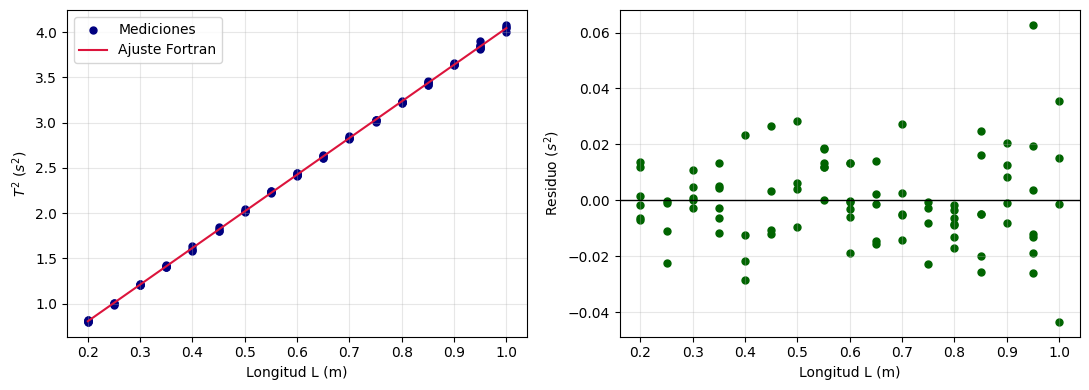

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Lee las cinco columnas producidas por el script de limpieza
datos = np.loadtxt("pendulo_limpio.dat")
longitud_m = datos[:, 1] / 100.0
numero_oscilaciones = datos[:, 3]
tiempo_total_s = datos[:, 4]

# # TODO: construya las variables linealizadas x=L y y=T^2
periodo_s = tiempo_total_s / numero_oscilaciones
x = longitud_m
y = periodo_s**2

# Copie los parámetros calculados por su programa Fortran
a = 4.048735
b = -0.002888

# Ordena x para dibujar una línea continua de izquierda a derecha
orden = np.argsort(x)
y_ajustada = a * x + b
residuos = y - y_ajustada

# Primer panel: mediciones y recta. Segundo panel: residuos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(x, y, s=25, color="navy", label="Mediciones")
ax1.plot(x[orden], y_ajustada[orden], color="crimson", label="Ajuste Fortran")
ax1.set_xlabel("Longitud L (m)")
ax1.set_ylabel(r"$T^2$ ($s^2$)")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.axhline(0.0, color="black", linewidth=1)
ax2.scatter(x, residuos, s=25, color="darkgreen")
ax2.set_xlabel("Longitud L (m)")
ax2.set_ylabel(r"Residuo ($s^2$)")
ax2.grid(alpha=0.3)

plt.tight_layout()
# Guarda la figura que se entregará con el informe
plt.savefig("ajuste_pendulo_y_residuos.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
from pathlib import Path
import numpy as np

# Función auxiliar que imprime un veredicto uniforme para cada prueba
resultados_pruebas = []

def informar(nombre, condicion, detalle=""):
    estado = "PASS" if condicion else "FAIL"
    print(f"{estado:<4}  {nombre}{detalle}")
    resultados_pruebas.append(bool(condicion))
    return bool(condicion)

# Archivos que debe producir el flujo de trabajo completo
archivo_datos = Path("pendulo_limpio.dat")
archivo_resultados = Path("resultados_ajuste.dat")
archivo_figura = Path("ajuste_pendulo_y_residuos.png")

# Primer nivel: comprueba existencia antes de intentar leer
ok_datos = informar("Existe pendulo_limpio.dat", archivo_datos.exists())
ok_resultados = informar("Existe resultados_ajuste.dat", archivo_resultados.exists())
informar("Existe la figura", archivo_figura.exists() and archivo_figura.stat().st_size > 0 if archivo_figura.exists() else False)

# Segundo nivel: valida formatos y compara con un cálculo independiente
if ok_datos and ok_resultados:
    try:
        datos = np.atleast_2d(np.loadtxt(archivo_datos))
        resultados = np.loadtxt(archivo_resultados).reshape(-1)

        estructura_datos = datos.shape[1] == 5 and datos.shape[0] >= 2
        estructura_resultados = resultados.size == 5
        informar("Formato del archivo de datos", estructura_datos, f"  filas={datos.shape[0]}, columnas={datos.shape[1]}")
        informar("Formato del archivo de resultados", estructura_resultados, f"  valores={resultados.size}")

        if estructura_datos and estructura_resultados:
            # Reconstruye x=L y y=T^2 directamente desde los datos limpios
            longitud_m = datos[:, 1] / 100.0
            periodo_s = datos[:, 4] / datos[:, 3]
            x = longitud_m
            y = periodo_s**2
            n_ref = len(x)

            # Calcula los valores de referencia con las fórmulas del método
            sx = np.sum(x)
            sy = np.sum(y)
            sxx = np.sum(x*x)
            sxy = np.sum(x*y)
            den = n_ref*sxx - sx*sx
            a_ref = (n_ref*sxy - sx*sy) / den
            b_ref = (sy - a_ref*sx) / n_ref
            residuos_ref = y - (a_ref*x + b_ref)
            sse_ref = np.sum(residuos_ref**2)
            sst_ref = np.sum((y - np.mean(y))**2)
            r2_ref = 1.0 - sse_ref/sst_ref
            g_ref = 4.0*np.pi**2/a_ref

            # Compara, con tolerancia, cada resultado entregado por Fortran
            n_f, a_f, b_f, r2_f, g_f = resultados
            informar("Número de datos N", int(round(n_f)) == n_ref, f"  obtenido={n_f:g}, esperado={n_ref}")
            informar("Pendiente a", np.isclose(a_f, a_ref, rtol=1e-6, atol=1e-9), f"  obtenida={a_f:.8g}, esperada={a_ref:.8g}")
            informar("Intercepto b", np.isclose(b_f, b_ref, rtol=1e-6, atol=1e-9), f"  obtenido={b_f:.8g}, esperado={b_ref:.8g}")
            informar("Coeficiente R²", np.isclose(r2_f, r2_ref, rtol=1e-6, atol=1e-9), f"  obtenido={r2_f:.8g}, esperado={r2_ref:.8g}")
            informar("Gravedad g", np.isclose(g_f, g_ref, rtol=1e-6, atol=1e-9), f"  obtenida={g_f:.8g}, esperada={g_ref:.8g}")
            informar("Valor físico razonable de g", 7.0 < g_f < 12.0, f"  g={g_f:.5f} m/s²")
    except Exception as error:
        informar("No fue posible completar la verificación", False, f": {error}")

# Resumen que debe copiarse en el informe de una página
n_pass = sum(resultados_pruebas)
n_total = len(resultados_pruebas)
print(f"\nRESUMEN PASS/FAIL: {n_pass} de {n_total} pruebas pasaron.")

PASS  Existe pendulo_limpio.dat
PASS  Existe resultados_ajuste.dat
PASS  Existe la figura
PASS  Formato del archivo de datos  filas=89, columnas=5
PASS  Formato del archivo de resultados  valores=5
PASS  Número de datos N  obtenido=89, esperado=89
PASS  Pendiente a  obtenida=4.0487347, esperada=4.0487347
PASS  Intercepto b  obtenido=-0.0028878571, esperado=-0.0028878571
PASS  Coeficiente R²  obtenido=0.99974782, esperado=0.99974782
PASS  Gravedad g  obtenida=9.7508038, esperada=9.7508038
PASS  Valor físico razonable de g  g=9.75080 m/s²

RESUMEN PASS/FAIL: 11 de 11 pruebas pasaron.
